# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [5]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(71)

(train_images, train_labels), (test_images, test_labels) = keras.datasets.fashion_mnist.load_data()
train_images = train_images.astype(np.float32) / 255.0
test_images = test_images.astype(np.float32) / 255.0

categories = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
              "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print('Train:', train_images.shape, train_labels.shape)
print('Test:', test_images.shape, test_labels.shape)
print('Pixel range:', train_images.min(), 'to', train_images.max())
print('Class counts:', np.bincount(train_labels))

train_targets = keras.utils.to_categorical(train_labels, 10)
test_targets = keras.utils.to_categorical(test_labels, 10)
print('One-hot label example:', train_labels[0], '->', train_targets[0])

Train: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)
Pixel range: 0.0 to 1.0
Class counts: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]
One-hot label example: 9 -> [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


In [ ]:
# Inspect the shapes of the datasets


# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical



In [ ]:
import matplotlib.pyplot as plt
# Verify the data looks as expected


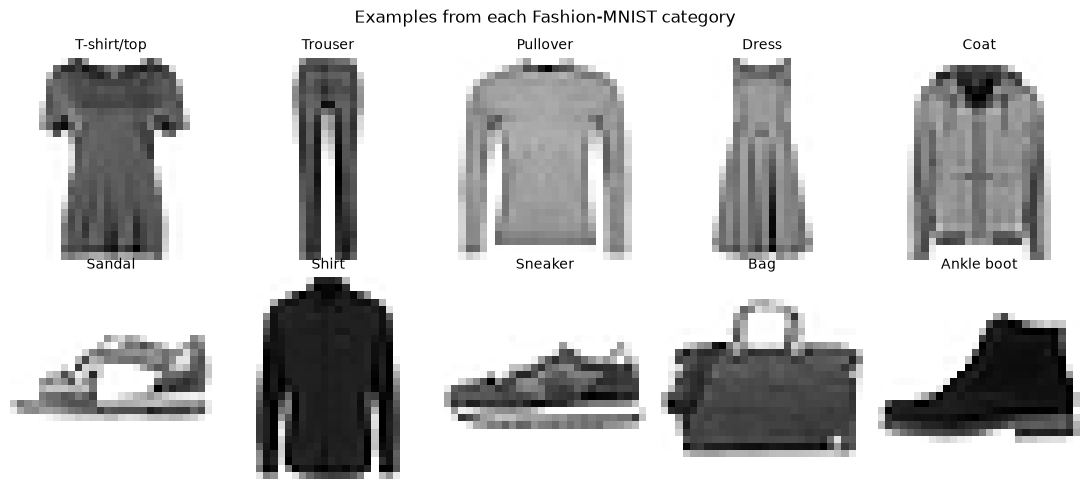

In [7]:
# Display one representative example of each of the ten categories.
fig, panels = plt.subplots(2, 5, figsize=(11, 5))
for category_id, panel in enumerate(panels.ravel()):
    image_id = np.flatnonzero(train_labels == category_id)[3]
    panel.imshow(train_images[image_id], cmap='gray_r')
    panel.set_title(categories[category_id], fontsize=10)
    panel.axis('off')
fig.suptitle('Examples from each Fashion-MNIST category')
plt.tight_layout()
plt.show()

Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

The images have consistent dimensions and each pixel now lies between 0 and 1. Some items like bags and trousers have distinctive outlines. Shirts, pullovers, and coats look quite similar at this resolution. Because the images are small and grayscale, the model must rely heavily on shape rather than colour or texture

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

In [8]:
from keras.models import Sequential
from keras.layers import Dense, Flatten

# Create a simple linear regression model
model = Sequential()
# You can use `model.add(<layer>)` to add layers to the model

# Compile the model using `model.compile()`

# Train the model with `model.fit()`

# Evaluate the model with `model.evaluate()`

In [9]:
linear_classifier = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(10)
], name='fashion_linear')

linear_classifier.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.CategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)
linear_classifier.summary()

linear_run = linear_classifier.fit(
    train_images, train_targets,
    epochs=4, batch_size=128, validation_split=0.1, verbose=2
)
linear_test_loss, linear_test_acc = linear_classifier.evaluate(
    test_images, test_targets, verbose=0
)
print(f'Linear baseline — test accuracy: {linear_test_acc:.3%}; loss: {linear_test_loss:.4f}')

Model: "fashion_linear"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/4
422/422 - 1s - 3ms/step - accuracy: 0.7532 - loss: 0.7491 - val_accuracy: 0.8157 - val_loss: 0.5503
Epoch 2/4
422/422 - 1s - 2ms/step - accuracy: 0.8247 - loss: 0.5239 - val_accuracy: 0.8347 - val_loss: 0.4894
Epoch 3/4
422/422 - 1s - 1ms/step - accuracy: 0.8382 - loss: 0.4805 - val_accuracy: 0.8418 - val_loss: 0.4629
Epoch 4/4
422/422 - 1s - 2ms/step - accuracy: 0.8445 - loss: 0.4578 - val_accuracy: 0.8463 - val_loss: 0.4475
Linear baseline — test accuracy: 83.510%; loss: 0.4814


Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

This model provides a useful starting point because it is computationally inexpensive. However, flattening converts each image into a long vector so the classifier does not directly exploit nearby pixels as image features. I will compare its measured test accuracy with the CNN in the next section.

# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

In [10]:
from keras.layers import Conv2D

# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create a simple CNN model
model = Sequential()

# Train the model

# Evaluate the model

In [ ]:
train_4d = train_images[..., None]
test_4d = test_images[..., None]

standard_cnn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(24, 3, activation='relu'),
    layers.MaxPooling2D(2),
    layers.Conv2D(48, 3, activation='relu'),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(80, activation='relu'),
    layers.Dense(10, activation='softmax')
], name='fashion_cnn')

standard_cnn.compile(optimizer=keras.optimizers.Adam(0.001),
                     loss='categorical_crossentropy', metrics=['accuracy'])
standard_cnn.summary()
cnn_run = standard_cnn.fit(train_4d, train_targets,
                           validation_split=0.1, epochs=4,
                           batch_size=128, verbose=2)
cnn_test_loss, cnn_test_acc = standard_cnn.evaluate(test_4d, test_targets, verbose=0)

print(f'CNN test accuracy: {cnn_test_acc:.3%}')
print(f'Linear baseline test accuracy: {linear_test_acc:.3%}')
print(f'Difference: {(cnn_test_acc-linear_test_acc)*100:+.2f} percentage points')

Model: "fashion_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 24)     │           240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 48)     │        10,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 48)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 80)             │        96,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 107,546 (420.10 KB)

 Trainable params: 107,546 (420.10 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/4
422/422 - 6s - 15ms/step - accuracy: 0.7863 - loss: 0.6002 - val_accuracy: 0.8338 - val_loss: 0.4541
Epoch 2/4
422/422 - 5s - 12ms/step - accuracy: 0.8634 - loss: 0.3827 - val_accuracy: 0.8647 - val_loss: 0.3656
Epoch 3/4
422/422 - 5s - 12ms/step - accuracy: 0.8779 - loss: 0.3387 - val_accuracy: 0.8792 - val_loss: 0.3316
Epoch 4/4
422/422 - 5s - 12ms/step - accuracy: 0.8875 - loss: 0.3099 - val_accuracy: 0.8873 - val_loss: 0.3115
CNN test accuracy: 88.150%
Linear baseline test accuracy: 83.510%
Difference: +4.64 percentage points


Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

The printed difference shows whether convolutional feature extraction helped on this run. A higher CNN accuracy would be consistent with its ability to recognize spatial structure in the clothing images. The comparison is empirical: a CNN does not automatically outperform every simpler model under every training setup

# 3. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

In [ ]:
sampling_rng = np.random.default_rng(71)
sample_ids = sampling_rng.choice(len(train_4d), size=12000, replace=False)
trial_images = train_4d[sample_ids]
trial_targets = train_targets[sample_ids]

def make_cnn(first_filters=24, dropout=0.0):
    network = keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(first_filters, 3, activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(first_filters * 2, 3, activation='relu'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(80, activation='relu'),
        layers.Dropout(dropout),
        layers.Dense(10, activation='softmax')
    ])
    network.compile(optimizer=keras.optimizers.Adam(0.001),
                      loss='categorical_crossentropy', metrics=['accuracy'])
    return network

trial_records = []

def test_setting(first_filters, dropout):
    keras.utils.set_random_seed(71)
    network = make_cnn(first_filters, dropout)
    run = network.fit(trial_images, trial_targets, validation_split=0.2,
                      epochs=3, batch_size=128, verbose=2)
    record = {'filters': first_filters, 'dropout': dropout,
              'val_accuracy': max(run.history['val_accuracy']),
              'val_loss': min(run.history['val_loss'])}
    trial_records.append(record)
    print(record)

for width in [12, 24, 48]:
    test_setting(width, 0.0)

width_table = pd.DataFrame(trial_records)
display(width_table.round(4))

Epoch 1/3
75/75 - 2s - 25ms/step - accuracy: 0.5953 - loss: 1.2471 - val_accuracy: 0.7287 - val_loss: 0.7333
Epoch 2/3
75/75 - 1s - 10ms/step - accuracy: 0.7616 - loss: 0.6380 - val_accuracy: 0.7733 - val_loss: 0.5888
Epoch 3/3
75/75 - 1s - 10ms/step - accuracy: 0.7972 - loss: 0.5518 - val_accuracy: 0.8096 - val_loss: 0.5240
{'filters': 12, 'dropout': 0.0, 'val_accuracy': 0.809583306312561, 'val_loss': 0.5239697694778442}
Epoch 1/3
75/75 - 2s - 29ms/step - accuracy: 0.6503 - loss: 1.0743 - val_accuracy: 0.7442 - val_loss: 0.6795
Epoch 2/3
75/75 - 1s - 14ms/step - accuracy: 0.7785 - loss: 0.5958 - val_accuracy: 0.7933 - val_loss: 0.5378
Epoch 3/3
75/75 - 1s - 15ms/step - accuracy: 0.8121 - loss: 0.5094 - val_accuracy: 0.8217 - val_loss: 0.4861
{'filters': 24, 'dropout': 0.0, 'val_accuracy': 0.8216666579246521, 'val_loss': 0.4860844910144806}
Epoch 1/3
75/75 - 4s - 58ms/step - accuracy: 0.6869 - loss: 0.9008 - val_accuracy: 0.7721 - val_loss: 0.6003
Epoch 2/3
75/75 - 2s - 31ms/step - acc

,filters,dropout,val_accuracy,val_loss
0,12,0.0,0.8096,0.5240
1,24,0.0,0.8217,0.4861
2,48,0.0,0.8383,0.4347


Epoch 1/3
75/75 - 4s - 54ms/step - accuracy: 0.6354 - loss: 1.0542 - val_accuracy: 0.7788 - val_loss: 0.5881
Epoch 2/3
75/75 - 2s - 33ms/step - accuracy: 0.7732 - loss: 0.6229 - val_accuracy: 0.8071 - val_loss: 0.5023
Epoch 3/3
75/75 - 2s - 31ms/step - accuracy: 0.8048 - loss: 0.5259 - val_accuracy: 0.8433 - val_loss: 0.4447
{'filters': 48, 'dropout': 0.3, 'val_accuracy': 0.8433333039283752, 'val_loss': 0.44465628266334534}


,filters,dropout,val_accuracy,val_loss,label
0,12,0.0,0.8096,0.5240,"12 filters, dropout=0.0"
1,24,0.0,0.8217,0.4861,"24 filters, dropout=0.0"
2,48,0.0,0.8383,0.4347,"48 filters, dropout=0.0"
3,48,0.3,0.8433,0.4447,"48 filters, dropout=0.3"


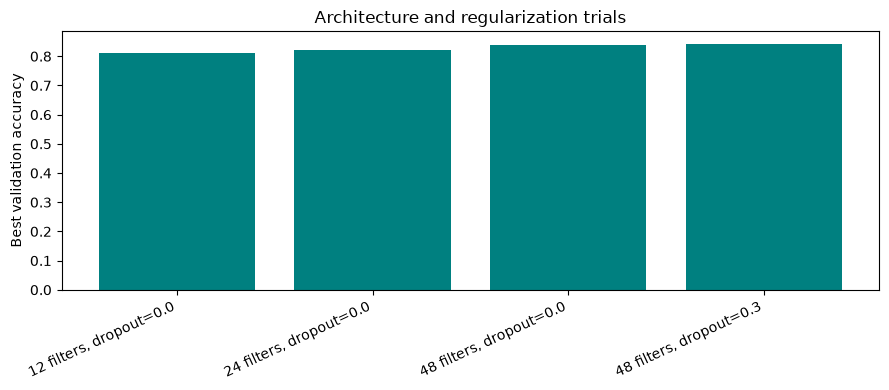

Chosen using validation accuracy: 48 filters, dropout=0.3
Dropout effect at 48 filters: +0.50 percentage points


In [13]:
# Test dropout only after identifying the strongest no-dropout filter setting.
chosen_width = int(max(trial_records, key=lambda item: item['val_accuracy'])['filters'])
test_setting(chosen_width, 0.30)

trial_table = pd.DataFrame(trial_records)
trial_table['label'] = trial_table.apply(
    lambda row: f"{int(row['filters'])} filters, dropout={row['dropout']:.1f}", axis=1)
display(trial_table.round(4))

plt.figure(figsize=(9, 4))
plt.bar(trial_table['label'], trial_table['val_accuracy'], color='teal')
plt.ylabel('Best validation accuracy')
plt.title('Architecture and regularization trials')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

winning_trial = max(trial_records, key=lambda item: item['val_accuracy'])
best_width = int(winning_trial['filters'])
best_dropout = float(winning_trial['dropout'])
print(f'Chosen using validation accuracy: {best_width} filters, dropout={best_dropout}')

plain = next(item for item in trial_records if item['filters'] == chosen_width and item['dropout'] == 0)
regularized = next(item for item in trial_records if item['filters'] == chosen_width and item['dropout'] == 0.30)
print(f"Dropout effect at {chosen_width} filters: "
      f"{100 * (regularized['val_accuracy']-plain['val_accuracy']):+.2f} percentage points")

Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

Increasing filter count increases the network's ability to represent image patterns but also adds parameters and computation. Dropout can reduce dependence on individual neurons, although it may not help when training is short. The table and chart show which settings performed best on the validation data. I avoid using test accuracy to select the winner.

# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

Epoch 1/5
422/422 - 13s - 30ms/step - accuracy: 0.7663 - loss: 0.6406 - val_accuracy: 0.8515 - val_loss: 0.3986
Epoch 2/5
422/422 - 12s - 29ms/step - accuracy: 0.8561 - loss: 0.4069 - val_accuracy: 0.8742 - val_loss: 0.3393
Epoch 3/5
422/422 - 12s - 28ms/step - accuracy: 0.8712 - loss: 0.3586 - val_accuracy: 0.8817 - val_loss: 0.3122
Epoch 4/5
422/422 - 14s - 33ms/step - accuracy: 0.8818 - loss: 0.3253 - val_accuracy: 0.8888 - val_loss: 0.3034
Epoch 5/5
422/422 - 14s - 33ms/step - accuracy: 0.8906 - loss: 0.3031 - val_accuracy: 0.8948 - val_loss: 0.2818


,Model,Test accuracy,Test loss
0,Linear baseline,0.8351,0.4814
1,Initial CNN,0.8815,0.3274
2,Tuned CNN,0.8924,0.3008


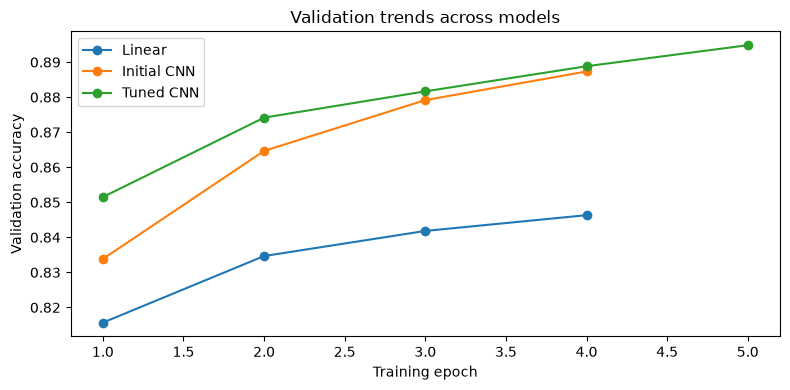

Final versus linear: +5.73 percentage points
Final versus initial CNN: +1.09 percentage points
In this run, tuning improved on the initial CNN.


In [14]:
keras.utils.set_random_seed(171)
final_classifier = make_cnn(best_width, best_dropout)
final_run = final_classifier.fit(train_4d, train_targets,
                                 epochs=5, batch_size=128,
                                 validation_split=0.1, verbose=2)
final_test_loss, final_test_acc = final_classifier.evaluate(
    test_4d, test_targets, verbose=0)

summary = pd.DataFrame({
    'Model': ['Linear baseline', 'Initial CNN', 'Tuned CNN'],
    'Test accuracy': [linear_test_acc, cnn_test_acc, final_test_acc],
    'Test loss': [linear_test_loss, cnn_test_loss, final_test_loss]
})
display(summary.round(4))

plt.figure(figsize=(8, 4))
for title, run in [('Linear', linear_run), ('Initial CNN', cnn_run), ('Tuned CNN', final_run)]:
    plt.plot(range(1, len(run.history['val_accuracy']) + 1),
             run.history['val_accuracy'], marker='o', label=title)
plt.xlabel('Training epoch')
plt.ylabel('Validation accuracy')
plt.title('Validation trends across models')
plt.legend()
plt.tight_layout()
plt.show()

print(f'Final versus linear: {(final_test_acc - linear_test_acc)*100:+.2f} percentage points')
print(f'Final versus initial CNN: {(final_test_acc - cnn_test_acc)*100:+.2f} percentage points')
if final_test_acc > cnn_test_acc:
    print('In this run, tuning improved on the initial CNN.')
elif final_test_acc < cnn_test_acc:
    print('In this run, the initial CNN retained the higher test accuracy.')
else:
    print('The two CNNs obtained the same test accuracy in this run.')

Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

The final table reports the observed accuracy. The selected CNN may or may not outperform the initial CNN: short training runs and the smaller experiment subset can affect which configuration wins. A logical next step would be to try longer training with early stopping, compare several random seeds, or examine misclassified shirts and coats. Those changes should still be decided using validation data rather than test results.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/09/2026`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.